# Neutral penetration analysis

We have previously identified the discrepency of neutral penetration level between fluid and kinetic model. 

In [1]:
# %matplotlib widget


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os, sys, pathlib, shlex, subprocess
import xbout
import scipy
import xhermes
# from xhermes import *


sys.path.append(r"/Users/zero/workspace/phd_work/hms_output/sdtools")
sys.path.append(r"/Users/zero/workspace/phd_work/hms_output/hermes3-2dplots/pltool")
# sys.path.append(r"/users/jpm590/2dspace/post-processing/sdtools/")
# sys.path.append(r"/users/jpm590/2dspace/post-processing/xBOUT/")

# from xbout.load import *
# from xbout.boutdataarray import *

from hermes3.utils import *

from code_comparison.solps_pp import *
from hermes3.fluxes import *
from hermes3.case_db import *
from hermes3.load import *
from hermes3.named_selections import *
from hermes3.plotting import *
from hermes3.grid_fields import *
from hermes3.accessors import *
from hermes3.selectors import *
from common import setup_matplotlib, adapt_solps_conventions

%load_ext autoreload
%autoreload 2
print("Done")

Done


In [2]:
db = CaseDB(
    case_dir = r"/Users/zero/workspace/phd_work/hms_output",
    grid_dir = r"/Users/zero/workspace/phd_work/hms_output/gridfile"
)

toload = [
    dict(name="260923_highrsl_fixplsbg_fromsolps_1e21_roomT", id="260923_highrsl_fixplsbg_fromsolps_1e21_roomT", unnormalise_geom = True, use_xhermes = True, squash = True),
]

cs = {}
for case in toload:
    cs[case["name"]] = db.load_case_2D(case["id"], use_squash = case["squash"], verbose = True)

    cs[case["name"]].extract_2d_tokamak_geometry()

/Users/zero/workspace/phd_work/hms_output/xhermes/lib/python3.12/site-packages/boutdata/data.py:762: AlwaysWarning: While building x, y, z coordinate arrays, an exception occured: [Errno 2] No such file or directory: '"CDN_46895_nowallpump_fixplsbg_fromsolps_hermes_1e21_roomT_260923.nc"'
Evaluating non-scalar options not available
  alwayswarn(


- Reading case 260923_highrsl_fixplsbg_fromsolps_1e21_roomT
-----------------------
- Looking for squash file
- Squash file found. squash date 09/25/2026, 15:11:55, dmp file date 09/23/2026, 13:54:14


/Users/zero/workspace/phd_work/hms_output/xhermes/lib/python3.12/site-packages/boutdata/data.py:762: AlwaysWarning: While building x, y, z coordinate arrays, an exception occured: 'PosixPath' object has no attribute 'split'
Evaluating non-scalar options not available
  alwayswarn(
/Users/zero/workspace/phd_work/hms_output/xBOUT/xbout/load.py:1294: UserWarning: Will drop all variables containing the dimensions 'closed_wall' because they are not recognised
  warn(



Unnormalising with xHermes


#### Choose your datatset

In [3]:
ds = cs["260923_highrsl_fixplsbg_fromsolps_1e21_roomT"].ds.isel(t=-1)

# SOLPS
solps_path = "../ref_puff1e21_radbc0_mirrorsides_atoms_recyct0p99_nofluxlim_novis_nocorrcore_corebccon8_ionisingcore_lluciani0"
bal = SOLPScase(solps_path)
bal = adapt_solps_conventions(bal)

[]


##### Intergrate fields in domains
Get the volume of the region you want.

You could possibly choose ([reference](https://github.com/mikekryjak/sdtools/blob/4242b6f0a55edf66d0b6e6f706bb7dc8515eb143/hermes3/deprecated/stuff.py#L155)): 
```python 
    core = ds.hermesm.select_region("core_noguards")
    domain = ds.hermesm.select_region("all_noguards")
    domain_volume = domain["dv"].values.sum()
```

In [4]:

# Hermes-3 
# domain = ds.hermesm.select_region("all_noguards")
# Nd = domain["Nd"] 
# dv = domain["dv"]
# Nd_total = (Nd * dv).sum(["x", "theta"]).squeeze()
# print(Nd.shape)
# print(f"[Hermes-3] Neutral in domain = {Nd_total.values:.3e} ")
# Nd_trans = domain["Nd"].transpose("theta","x")
# print(f"Nd_trans shape :{Nd_trans.shape}")

# Choose region manually
Nd_guard = ds["Nd"].transpose("theta","x")
print(f"Nd_guard shape: {Nd_guard.shape}")
pol_h = np.r_[2:72, 76:206] # poloidal: drop 0 1 , 72 73, 74 75 , 206 207
rad_h = np.r_[2:38]
# print(pol_h, rad_h)    
Nd = Nd_guard[pol_h, :][:, rad_h]
print(f"Nd shape: {Nd.shape}")
print(f"1st element is {Nd[0,0].values}")


# Nd_guard = ds["Nd"]
# print(f"Nd_guard shape: {Nd_guard.shape}")
# pol_h = np.r_[2:72, 76:206] # poloidal: drop 0 1 , 72 73, 74 75 , 206 207
# rad_h = np.r_[2:38]
# # print(pol_h, rad_h)    
# Nd = Nd_guard[rad_h, :][:, pol_h]
# print(f"Nd shape: {Nd.shape}")
# print(f"1st element is {Nd[0,0].values}")

# SOLPS
Na_guard  = bal.bal["Na"]
vol_guard = bal.g["vol"]
print(f"Na_guard shape :  {Na_guard.shape}")
# print(f"vol_guard shape :  {vol_guard.shape}")

# Make an index element 
# pol : 1, 2, 3, 4, 5, ... 71, 74, 75 ...., 202
# rad : 1, 2, 3, ... ,36
pol = np.r_[1:72, 74:203] # poloidal: drop 0, 72, 73, 203
rad = np.r_[1:37]        # radial:   0, 37 are guard cell

# vol = bal.g["vol"][pol,:][:,rad]          # [m^3], 去 guard cells
# print(f"vol shape {vol.shape}")
Na  = bal.bal["Na"][pol,:][:, rad]          # atoms   [m^-3]
# print(Na.values)
print(f"Na shape :  {Na.shape}")
print(f"1st element is {Na[0,0]}")
# Na_total = (Na * vol).sum()

# print(f"[SOLPS] Neutral atoms in domain = {Na_total:.3e} ")




Nd_guard shape: (208, 40)
Nd shape: (200, 36)
1st element is 1.4304043495540242e+18
Na_guard shape :  (204, 38)
Na shape :  (200, 36)
1st element is 3.5915800754196864e+17


1.0712463420120556e+18
Nd_full shape: (208, 40)


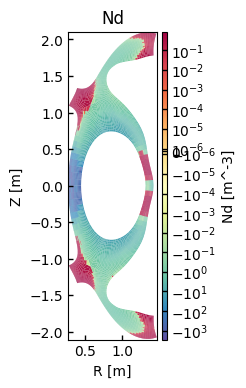

In [5]:
# Get the shape from original array and fill nan into the array
# np.full(shape, fiiling values)

# full_arr = np.full(ds["Nd"].shape, np.nan)
# Nd_transp = Nd.transpose("theta","x")
# print(f"Nd_transp shape = {Nd_transp.shape}")
# # Specify the location by ix and fill in the values into the array
# full_arr[np.ix_(pol_h, rad_h)] = np.asarray(Nd_transp) - np.asarray(Na)
# print(f"Nd_full shape: {full_arr.shape}")


# You can only use Hermes-3's variable to do transpose because you know the they 
# Can be transposed by "x" and "theta"
diff_full_arr = np.full(ds["Nd"].transpose("theta","x").shape, np.nan)
# Specify the location by ix and fill in the values into the array
diff_full_arr[np.ix_(pol_h, rad_h)] = np.asarray(Nd) - np.asarray(Na)
print(diff_full_arr[2,2])
print(f"Nd_full shape: {diff_full_arr.shape}")




# To get the full dataset for the arrary
diff_full = ds["Nd"].transpose("theta", "x").copy(data=diff_full_arr) 
diff_norm = diff_full/ds["Nd"].transpose("theta", "x")
fig, ax = plt.subplots()
# diff_norm.bout.polygon(ax=ax, cmap="RdBu_r", antialias=True,
diff_norm.bout.polygon(ax=ax, cmap="Spectral_r", antialias=True,
                logscale=True, separatrix=False, )
fig.savefig("diff.pdf")







Explanation:

Hermes-3 has larger amount of neutral at target comparing to SOLPS. At puff location, neutrals are more spread out than SOLPS

If we plot neutral atom seperately: 

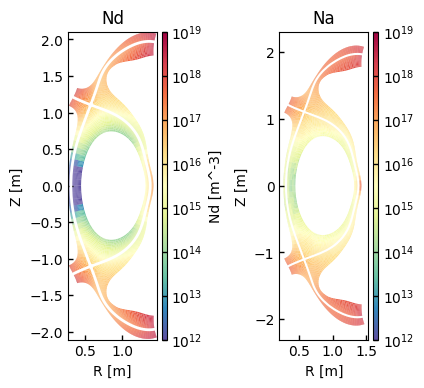

In [10]:

fig, ax = plt.subplots(1,2)
vmin = 1e12
vmax = 1e19
ds["Nd"].hermes.clear_guards().bout.polygon(
                ax=ax[0], cmap="Spectral_r", antialias=True,
                logscale=True, vmin = vmin, vmax=vmax)
bal.plot_2d("Na", ax=ax[1], cmap="Spectral_r", antialias=True,
                logscale=True, separatrix=True,vmin=vmin, vmax=vmax )




## Compare Vpol

Raw pfluxa (an array): [ 3.3138810e+21  2.7741974e+21  2.7564411e+21 ... -3.5400277e+21
 -3.3578369e+21 -3.2268148e+21]
pfluxa size = 7272, nx = 204, ny = 38, nx*ny = 7752


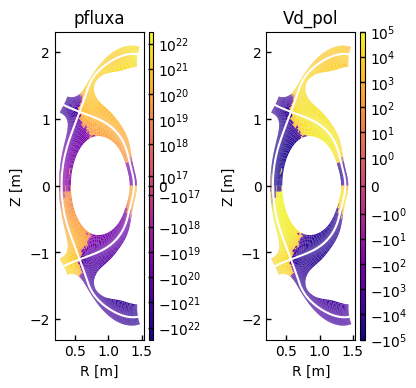

In [6]:
# Extract pfluxa from fort.44 and pad to (nx, ny)
import numpy as np
import builtins
filename = solps_path + "/fort.44"
var_name = "pfluxa"
with builtins.open(filename, 'r') as f:
    lines = f.readlines()

data_lines = []
found = False
for line in lines:
    if line.startswith(f"*eirene data field {var_name}"):
        found = True
        continue
    if found:
        if line.startswith("*"):
            break
        data_lines.append(line)

data = []
for line in data_lines:
    data.extend([float(x) for x in line.split()])

pfluxa = np.array(data)
print(f"Raw pfluxa (an array): {pfluxa}")

# Number of cells in balance.nc
nx, ny = bal.g["nx"], bal.g["ny"]
print(f"pfluxa size = {pfluxa.size}, nx = {nx}, ny = {ny}, nx*ny = {nx*ny}")
# print(f"Shape of pfluxa from fort.44: {np.shape(pfluxa)}")

# fort.44 outputs without guard cells: shape is (nx-2, ny-2)
# Fortran order ('F') means first dimension (poloidal) varies fastest.
pfluxa_inner = pfluxa.reshape((nx-2, ny-2), order='F')
# print(f"pfluxa_inner: {pfluxa_inner}")


# Pad with zeros to match SOLPS grid shape (nx, ny)
pfluxa_padded = np.zeros((nx, ny))
pfluxa_padded[1:-1, 1:-1] = pfluxa_inner
# print(pfluxa_padded)


fig, ax = plt.subplots(1,2)
# Plot using bal's plot_2d
# We need to flatten it since SOLPScase plot_2d expects a flattened array or internal data
try:
    # plot_2d uses the parameter as a title, and data for the values if provided
    bal.plot_2d(var_name, ax=ax[0], data=pfluxa_padded, logscale=True, cmap="plasma")
except Exception as e:
    print(f"Error plotting: {e}")



# --- Velocity Calculation ---
# Get Neutral Density from your SOLPScase (shape is already nx, ny)
Nd = bal.bal["Na"]
# Do a safe division: Vd = pfluxa / Nd (outputs 0 where Nd is 0)
Vd_pol = np.divide(pfluxa_padded, Nd, out=np.zeros_like(pfluxa_padded), where=(Nd!=0))
# Plot the new velocity array!
bal.plot_2d( "Vd_pol", ax=ax[1],data=Vd_pol, logscale=True,vmin= - 1e5, vmax=1e5, cmap="plasma")

##### Derive Vd_pol from Hermes-3

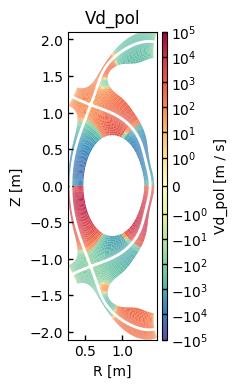

In [7]:
ds["Vd_pol"]=ds["Vd"]*abs(ds["Bpxy"] / abs(ds["Bxy"]))
fig, ax = plt.subplots()
ds["Vd_pol"].bout.polygon(ax = ax , cmap = "Spectral_r", antialias = True,logscale = True ,vmin= - 1e5, vmax=1e5)

## I love Link liu
Try to subtract variables that you think worth comparing, such as `Sd+_iz` `Edd+_cx` ...

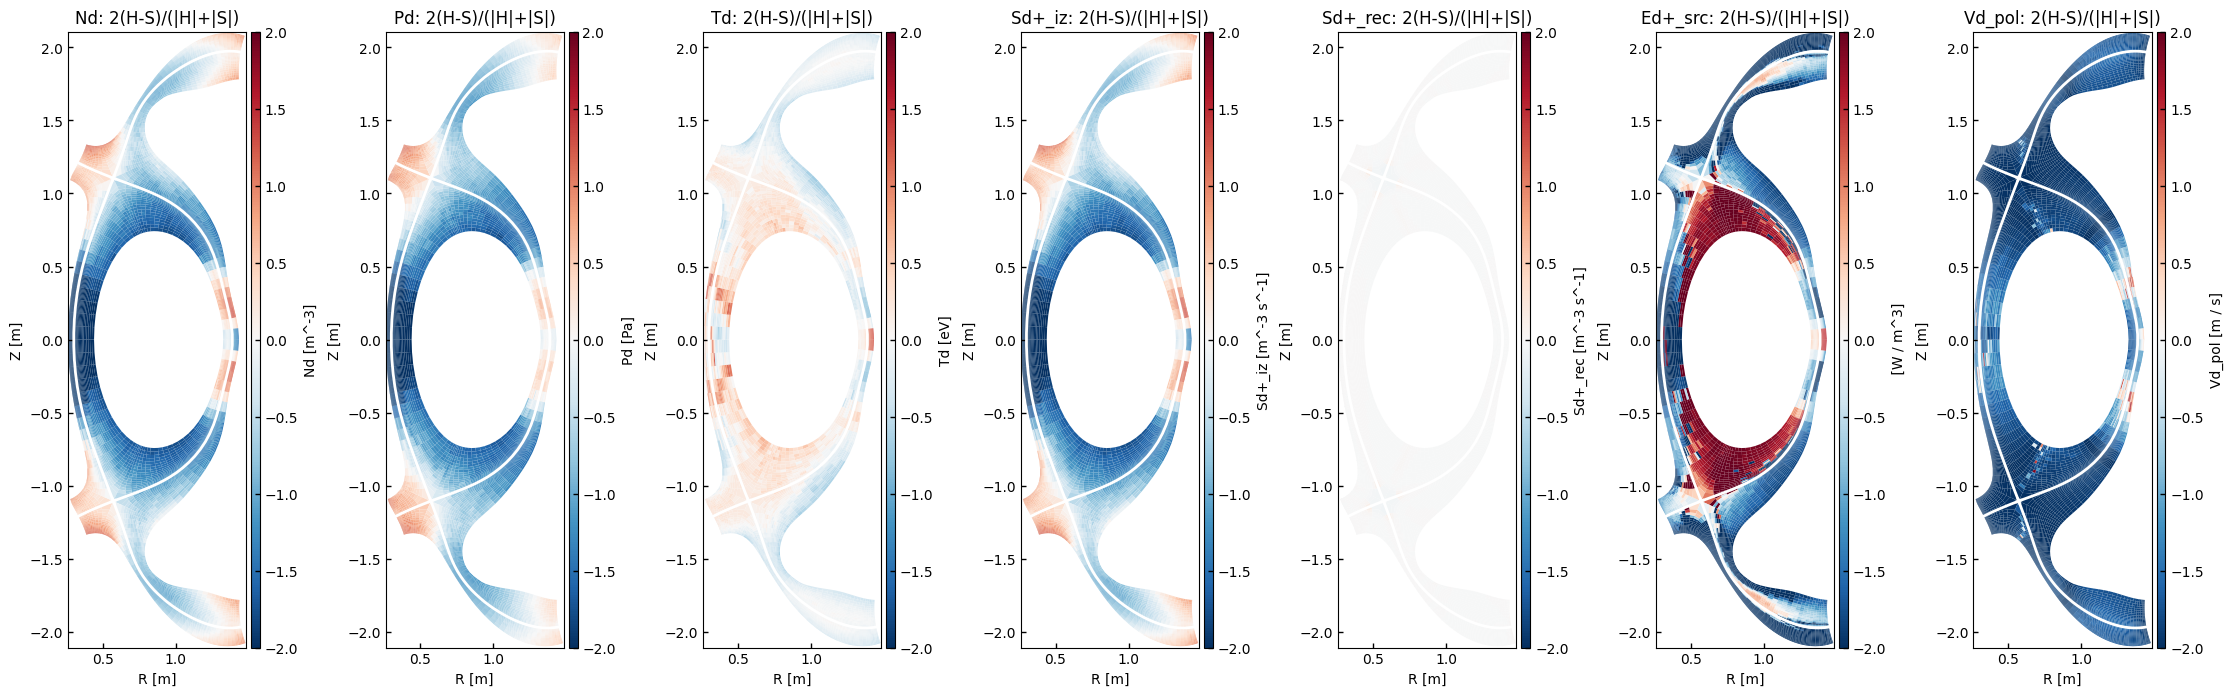

In [21]:
fields = {
    "Nd": (ds["Nd"], bal.bal["Na"]),
    "Pd": (ds["Pd"], bal.bal["Pa"]),
    "Td": (ds["Td"], bal.bal["Ta"]),
    "Sd+_iz" :(ds["Sd+_iz"], bal.bal["Sd+_iz"]),
    "Sd+_rec" :(np.abs(ds["Sd+_rec"]), np.abs(bal.bal["Sd+_rec"])),

    # hermes-3 Edd+_cx is sink of ion, source of neutral;
    # SOLPS is energy source of ion due to ion-neutral collision (cx+iz)
    # To obtain ion energy source due to cx and iz (matching to solps's eirene_mc_eapl_shi_bal),
    # We should sum up Ed+_iz and negative Edd+_cx
    
    "Ed+_src" :(ds["Ed+_iz"]-ds["Edd+_cx"], bal.bal["Edd+_cxiz"]),
    "Vd_pol": (np.abs(ds["Vd_pol"]), np.abs(Vd_pol))
}
pol_h = np.r_[2:72, 76:206] # poloidal: drop 0 1 , 72 73, 74 75 , 206 207
rad_h = np.r_[2:38]

pol_s = np.r_[1:71, 73:203] # poloidal: drop 0, 72, 73, 203
rad_s = np.r_[1:37]        # radial:   0, 37 are guard cell
# # print(pol_h, rad_h)    
# print(pol_s, rad_s)    
debug=False
symmetry=True
# fig, ax = plt.subplots(1, len(fields), figsize=(30, 60))
fig, ax = plt.subplots(1, len(fields), figsize=(4 * len(fields), 8))
for i, (field, (hdata, sdata)) in enumerate(fields.items()):
    # Handle with hermes-3 data
    h_guard = hdata.transpose("theta","x")
    # h_values = h_guard[pol_h, :][:, rad_h]

    # Handle with SOLPS data
    # s_values = sdata[pol_s,:][:, rad_s]
    h_values = np.asarray(h_guard[pol_h, :][:, rad_h])
    s_values = np.asarray(sdata[pol_s, :][:, rad_s])

    if debug:
        print(f"[H] {field}_guard shape: {h_guard.shape}")
        print(f"[H] {field}_values shape: {h_values.shape}")
        print(f"[S] {field}_guard shape :  {sdata.shape}")
        print(f"[S] {field}_values shape :  {s_values.shape}")

    if symmetry:
        # Symmetric relative difference, bounded in [-2, 2]
        rel = np.full(h_guard.shape, np.nan)
        denom = np.abs(h_values) + np.abs(s_values)
        rel[np.ix_(pol_h, rad_h)] = np.divide(
            2 * (h_values - s_values), denom,
            out=np.full_like(denom, np.nan), where=denom != 0,
        )
        diff_norm = h_guard.copy(data=rel)
        diff_norm.bout.polygon(ax=ax[i], cmap="RdBu_r", antialias=True,
                           logscale=False, vmin=-2, vmax=2, separatrix=True)
        ax[i].set_title(f"{field}: 2(H-S)/(|H|+|S|)")
    else:
        # Creat an array for subtraction result with hermes-3 shape
        diff_full_arr = np.full(hdata.transpose("theta","x").shape, np.nan)
        # Specify the location by ix and fill in the values into the array
        diff_full_arr[np.ix_(pol_h, rad_h)] = np.asarray(h_values) - np.asarray(s_values)

        print(f"Difference of {field} shape: {diff_full_arr.shape}")
        #  To get the full dataset for the arrary
        diff_full = hdata.transpose("theta", "x").copy(data=diff_full_arr) 
        diff_norm = diff_full/hdata.transpose("theta", "x")
        # diff_norm.bout.polygon(ax=ax, cmap="RdBu_r", antialias=True,
        diff_norm.bout.polygon(ax=ax[i], cmap="Spectral_r", antialias=True,
                    logscale=True, separatrix=True, )
        ax[i].set_title(f"{field}")



fig.savefig("diff.pdf")